# 地磁场测量实验 —— 亥姆霍兹线圈的空间磁场分布

**原始数据**：以线圈中心为原点、在两线圈之间的中平面内取 $x,y=0\sim0.3R$
（步长 $0.05R$）的 $7\times7$ 个点，测得传感器输出电压 $U$。

**物理原理**

亥姆霍兹线圈（半径 $R$、间距 $R$、通同向电流）在中心区域产生近似均匀的磁场。
中平面（$z=0$）内，理论磁场随径向距离缓慢下降：中心最大，
到 $\sqrt{x^2+y^2}=0.42R$ 的角点约降 1.6%。因此作中平面的 $B_x$–$(x,y)$
空间分布图，可以直观检验"中心均匀场"这一特点。

**处理思路**

1. 用表 11-1 的标定关系 $U=a+bB$ 把 49 个电压值换算成磁感应强度：
   $$B=\frac{U-a}{b},\qquad a=0.0065\ \mathrm{V},\ b=0.2509\ \mathrm{V/Gs}.$$
2. 作三维曲面图（$x$、$y$ 位置为横轴，$B$ 为竖轴，颜色表示 $B$ 的大小），
   网格即实测点，不作额外平滑或镜像对称。
3. 用椭圆积分算出亥姆霍兹线圈中平面的理论场分布，与实测比较量级与趋势。


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.font_manager as fm
from scipy.special import ellipk, ellipe

# ---------- 字体：英文用 Times New Roman，中文逐字回退到宋体 ----------
_installed = {f.name for f in fm.fontManager.ttflist}
_cjk_candidates = ['SimSun', 'STSong', 'Songti SC', 'Noto Serif SC',
                   'Source Han Serif SC', 'SimHei', 'Microsoft YaHei']
CJK_FONT = next((f for f in _cjk_candidates if f in _installed), 'DejaVu Sans')

rcParams['font.family']        = ['Times New Roman', CJK_FONT, 'DejaVu Sans']
rcParams['mathtext.fontset']   = 'stix'
rcParams['axes.unicode_minus'] = False
rcParams['figure.facecolor']   = 'white'
rcParams['savefig.facecolor']  = 'white'

pd.set_option('display.unicode.east_asian_width', True)

# ---------- 原始数据：行 = y，列 = x（单位 /R） ----------
xy = np.array([0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30])
U = np.array([
    [1.019, 1.017, 1.016, 1.016, 1.015, 1.012, 1.008],   # y = 0
    [1.018, 1.017, 1.017, 1.016, 1.015, 1.012, 1.007],   # y = 0.05R
    [1.017, 1.017, 1.017, 1.016, 1.015, 1.013, 1.007],   # y = 0.10R
    [1.016, 1.016, 1.016, 1.017, 1.017, 1.015, 1.012],   # y = 0.15R
    [1.016, 1.015, 1.016, 1.017, 1.017, 1.019, 1.017],   # y = 0.20R
    [1.015, 1.016, 1.018, 1.020, 1.023, 1.024, 1.029],   # y = 0.25R
    [1.013, 1.014, 1.016, 1.021, 1.025, 1.029, 1.031],   # y = 0.30R
])

# ---------- 标定：与图 1 相同的 U–B 关系 ----------
B_cal = np.array([-6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6], dtype=float)
U_cal = np.array([-1.464, -1.242, -1.008, -0.766, -0.518, -0.263, 0.002,
                   0.261, 0.518, 0.774, 1.024, 1.266, 1.500])
b_fit, a_fit = np.polyfit(B_cal, U_cal, 1)
print(f'标定关系 : U = {a_fit:.4f} + {b_fit:.4f} · B   (V, Gs)')

B = (U - a_fit) / b_fit                                  # 磁感应强度 B/Gs

df_U = pd.DataFrame(U, index=[f'y={v:g}R' for v in xy],
                    columns=[f'x={v:g}R' for v in xy])
df_B = pd.DataFrame(B.round(3), index=[f'y={v:g}R' for v in xy],
                    columns=[f'x={v:g}R' for v in xy])
display(df_U)
display(df_B)

print(f'中心 B = {B[0, 0]:.3f} Gs，最小 {B.min():.3f} Gs，最大 {B.max():.3f} Gs')
print(f'起伏 = {(B.max() - B.min()):.3f} Gs，为中心值的 {(B.max() - B.min()) / B[0, 0] * 100:.2f}%')
print(f'y=0 行：x 由 0 到 0.3R，B 变化 {(B[0, -1] - B[0, 0]) / B[0, 0] * 100:+.2f}%')
print(f'x=0 列：y 由 0 到 0.3R，B 变化 {(B[-1, 0] - B[0, 0]) / B[0, 0] * 100:+.2f}%')
print(f'对角：中心到 (0.3R, 0.3R)，B 变化 {(B[-1, -1] - B[0, 0]) / B[0, 0] * 100:+.2f}%')

# ---------- 理论：一对半径 R、间距 R 的线圈在中平面的轴向场 ----------
def loop_Bz(rho, dz, aa=1.0):
    """半径 aa 的圆环在 (径向 rho, 轴向距离 dz) 处的 B_z（相对单位）。"""
    m = 4 * aa * rho / ((aa + rho) ** 2 + dz ** 2)
    K, E = ellipk(m), ellipe(m)
    return (1 / np.sqrt((aa + rho) ** 2 + dz ** 2)
            * (K + (aa ** 2 - rho ** 2 - dz ** 2) / ((aa - rho) ** 2 + dz ** 2) * E))


def helmholtz_Bz(x, y):
    """亥姆霍兹线圈中平面（z=0）的轴向场。"""
    return loop_Bz(np.hypot(x, y), -0.5) + loop_Bz(np.hypot(x, y), 0.5)


B0_th = helmholtz_Bz(0, 0)
print(f'理论中平面比值： (0.3R,0) {helmholtz_Bz(0.3, 0) / B0_th:.4f}，'
      f'(0,0.3R) {helmholtz_Bz(0, 0.3) / B0_th:.4f}，'
      f'(0.3R,0.3R) {helmholtz_Bz(0.3, 0.3) / B0_th:.4f}')


标定关系 : U = 0.0065 + 0.2509 · B   (V, Gs)


,x=0R,x=0.05R,x=0.1R,x=0.15R,x=0.2R,x=0.25R,x=0.3R
y=0R,1.019,1.017,1.016,1.016,1.015,1.012,1.008
y=0.05R,1.018,1.017,1.017,1.016,1.015,1.012,1.007
y=0.1R,1.017,1.017,1.017,1.016,1.015,1.013,1.007
y=0.15R,1.016,1.016,1.016,1.017,1.017,1.015,1.012
y=0.2R,1.016,1.015,1.016,1.017,1.017,1.019,1.017
y=0.25R,1.015,1.016,1.018,1.020,1.023,1.024,1.029
y=0.3R,1.013,1.014,1.016,1.021,1.025,1.029,1.031


,x=0R,x=0.05R,x=0.1R,x=0.15R,x=0.2R,x=0.25R,x=0.3R
y=0R,4.035,4.027,4.023,4.023,4.019,4.007,3.991
y=0.05R,4.031,4.027,4.027,4.023,4.019,4.007,3.987
y=0.1R,4.027,4.027,4.027,4.023,4.019,4.011,3.987
y=0.15R,4.023,4.023,4.023,4.027,4.027,4.019,4.007
y=0.2R,4.023,4.019,4.023,4.027,4.027,4.035,4.027
y=0.25R,4.019,4.023,4.031,4.039,4.051,4.055,4.075
y=0.3R,4.011,4.015,4.023,4.043,4.059,4.075,4.083


中心 B = 4.035 Gs，最小 3.987 Gs，最大 4.083 Gs
起伏 = 0.096 Gs，为中心值的 2.37%
y=0 行：x 由 0 到 0.3R，B 变化 -1.09%
x=0 列：y 由 0 到 0.3R，B 变化 -0.59%
对角：中心到 (0.3R, 0.3R)，B 变化 +1.19%
理论中平面比值： (0.3R,0) 0.9962，(0,0.3R) 0.9962，(0.3R,0.3R) 0.9836


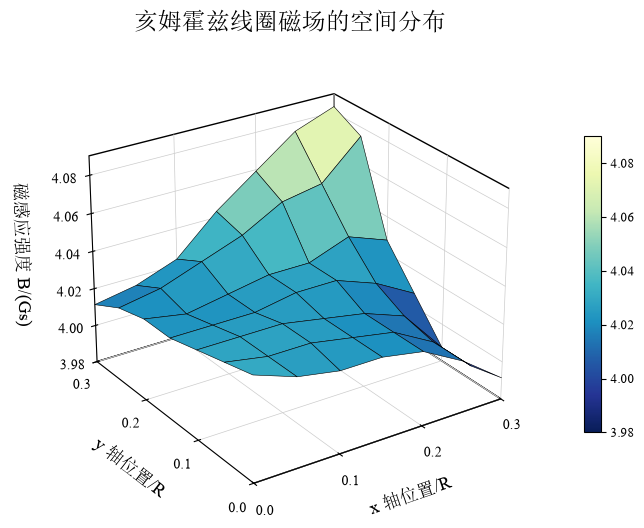

In [2]:
# ================= 图 4：空间磁场分布三维曲面 =================
X, Y = np.meshgrid(xy, xy)                 # 行 = y，列 = x

fig = plt.figure(figsize=(8.0, 6.2))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(X, Y, B, cmap='YlGnBu_r',
                       rstride=1, cstride=1,           # 每个网格面都画出来
                       edgecolor='black', linewidth=0.4,
                       antialiased=True, shade=False,
                       vmin=3.98, vmax=4.09)

ax.set_xlim(0, 0.3)
ax.set_ylim(0, 0.3)
ax.set_zlim(3.98, 4.09)
ax.set_xticks(np.arange(0, 0.31, 0.1))
ax.set_yticks(np.arange(0, 0.31, 0.1))
ax.set_zticks(np.arange(3.98, 4.09, 0.02))
ax.tick_params(labelsize=10, pad=3)
ax.set_box_aspect((1, 1, 0.78))

ax.set_xlabel('x 轴位置/R', fontsize=13, labelpad=8)
ax.set_ylabel('y 轴位置/R', fontsize=13, labelpad=8)
ax.set_zlabel('磁感应强度 B/(Gs)', fontsize=13, labelpad=10)
ax.set_title('亥姆霍兹线圈磁场的空间分布', fontsize=17, pad=16)

# 白色面板、黑色边框（Origin 默认外观）
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.pane.set_facecolor('white')
    axis.pane.set_edgecolor('black')
    axis.pane.set_alpha(1.0)
    axis._axinfo['grid']['color'] = (0.8, 0.8, 0.8, 1)
    axis._axinfo['grid']['linewidth'] = 0.5

ax.view_init(elev=26, azim=-124)

cb = fig.colorbar(surf, ax=ax, shrink=0.62, pad=0.10, aspect=18)
cb.set_ticks(np.arange(3.98, 4.09, 0.02))
cb.ax.tick_params(labelsize=9)
cb.outline.set_linewidth(0.8)

plt.savefig('图4_亥姆霍兹线圈_空间磁场分布.png', dpi=300, bbox_inches='tight')
plt.show()


## 结果分析

**1. 整体起伏很小，中心区域基本均匀**

49 个点换算后的磁场在 **3.987–4.083 Gs** 之间，中心 $(0,0)$ 为 4.035 Gs，
全场起伏只有 0.096 Gs，约为中心值的 **2.4%**；$|x|,|y|\le0.2R$ 的中央区域
读数集中在 4.019–4.035 Gs，变化不超过 0.4%。这印证了亥姆霍兹线圈
"中心区域产生近均匀磁场"的特点。

**2. 分布趋势与理论对照**

- 沿 $x$ 轴（$y=0$）：从 4.035 单调降到 3.991（$-1.1\%$）。理论在该方向只降约
  0.4%，方向一致但实测降得更快。
- 沿 $y$ 轴（$x=0$）：从 4.035 降到 4.011（$-0.6\%$）。
- 沿对角线到角点 $(0.3R,0.3R)$：实测**升到 4.083（$+1.2\%$）**，
  而理论应降到 $0.984B_0$（$-1.6\%$），趋势相反。
- 最低点出现在 $(0.3R,0.05R)$ 和 $(0.3R,0.10R)$ 两处（3.987 Gs）。

也就是说：曲面在靠 $x$ 轴的一侧有一道浅"谷"，靠远角的一侧反而抬起；
起伏量级与理论相当，但空间形状没有复现理论上的"径向单调缓降"。

**3. 误差来源**

- **读数随时间的漂移。** 按 $y$ 逐行测量，后两行（$y=0.25R,0.3R$）整体比前几行高
  0.3%–1.0%，且 $x$ 越大差得越多。线圈电流或放大器零点随时间缓慢漂移时，
  就会产生这种"越测越高"的倾斜，是角点抬高的主要原因。
- **传感器姿态。** 在导轨上移动传感器时，敏感轴与线圈轴线不再严格平行，
  读到的分量随之改变。
- **位置与几何误差。** 导轨定位、线圈中心与坐标原点未完全重合。
- 标定带来的整体比例误差约 1%（中心 4.035 Gs 对标准 4 Gs），不影响相对分布。

**4. 结论**

空间分布图显示：亥姆霍兹线圈中平面中心区域磁场高度均匀（起伏约 2%），
沿 $x$、$y$ 方向缓慢下降，边缘略有塌落，符合"中心均匀场、向外缓降"的基本特点。
但角点读数异常升高、与理论趋势相反，说明本次测量存在以时间漂移为主的系统误差，
因此这张图适合作**定性**说明，不足以定量检验中平面场的细微分布。
